# CBP industry analysis: Colorado, Kansas, Missouri, Texas (2020–2023)

Census **County Business Patterns** (CBP), by two-digit NAICS sector.

- `data/processed/cbp_state_industry_2020_2023.csv`: one row per year × state × sector (320 rows)
- `data/processed/cbp_county_industry_2020_2023.csv`: one row per year × county × sector (~32,000 rows)

Build or refresh the data from the project root with `python -m src.ingestion.fetch_census`.

**Read before comparing years**
- `employees` counts the **mid-March** pay period. 2020 employment is mostly *before* the COVID-19 lockdowns, while 2020 payroll covers the whole year.
- CBP adds small random noise to protect businesses, so tiny changes are not meaningful.
- All-sector totals (NAICS `00`) are excluded, so summing sectors gives the state total. Summing *counties* does not: CBP withholds some small county cells (see the last section).
- Payroll is in **$1,000s** and not adjusted for inflation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

DATA_DIR = Path("../data/processed")
CODES = {"state_fips": str, "county_fips": str, "naics_code": str}  # keep leading zeros

state = pd.read_csv(DATA_DIR / "cbp_state_industry_2020_2023.csv", dtype=CODES)
county = pd.read_csv(DATA_DIR / "cbp_county_industry_2020_2023.csv", dtype=CODES)
MEASURES = ["establishments", "employees", "annual_payroll_thousands"]

# Short sector names for chart labels.
SHORT = {
    "11": "Agriculture", "21": "Mining, oil & gas", "22": "Utilities", "23": "Construction",
    "31-33": "Manufacturing", "42": "Wholesale", "44-45": "Retail", "48-49": "Transport & warehousing",
    "51": "Information", "52": "Finance & insurance", "53": "Real estate", "54": "Professional services",
    "55": "Management of companies", "56": "Admin & waste services", "61": "Education",
    "62": "Health care", "71": "Arts & recreation", "72": "Accommodation & food",
    "81": "Other services", "99": "Not classified",
}
state["sector"] = state["naics_code"].map(SHORT)
county["sector"] = county["naics_code"].map(SHORT)

# Chart styling: quiet axes, hairline grid, fixed colors per state.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
STATE_COLORS = {"Colorado": "#2a78d6", "Kansas": "#eb6834", "Missouri": "#1baf7a", "Texas": "#eda100"}
STATE_ORDER = list(STATE_COLORS)
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
RED_GRAY_BLUE = LinearSegmentedColormap.from_list("change", ["#e34948", "#f0efec", "#2a78d6"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.edgecolor": AXIS, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})

## Row counts

In [2]:
print("State level: rows by year and state")
display(state.pivot_table(index="year", columns="state_name", values="naics_code", aggfunc="count", margins=True, margins_name="Total"))

print("County level: rows by year and state")
display(county.pivot_table(index="year", columns="state_name", values="naics_code", aggfunc="count", margins=True, margins_name="Total"))

print("Missing values per column (state, county):")
display(pd.DataFrame({"state": state[MEASURES].isna().sum(), "county": county[MEASURES].isna().sum()}))

State level: rows by year and state


state_name,Colorado,Kansas,Missouri,Texas,Total
year,,,,,
2020,20,20,20,20,80
2021,20,20,20,20,80
2022,20,20,20,20,80
2023,20,20,20,20,80
Total,80,80,80,80,320


County level: rows by year and state


state_name,Colorado,Kansas,Missouri,Texas,Total
year,,,,,
2020,983,1466,1795,3771,8015
2021,984,1459,1786,3758,7987
2022,985,1454,1787,3774,8000
2023,984,1455,1771,3774,7984
Total,3936,5834,7139,15077,31986


Missing values per column (state, county):


,state,county
establishments,0,0
employees,0,0
annual_payroll_thousands,0,0


## Industry mix in 2023

Each column shows how a state's employees split across sectors (columns add to 100%). Sectors are sorted by their combined size across all four states.

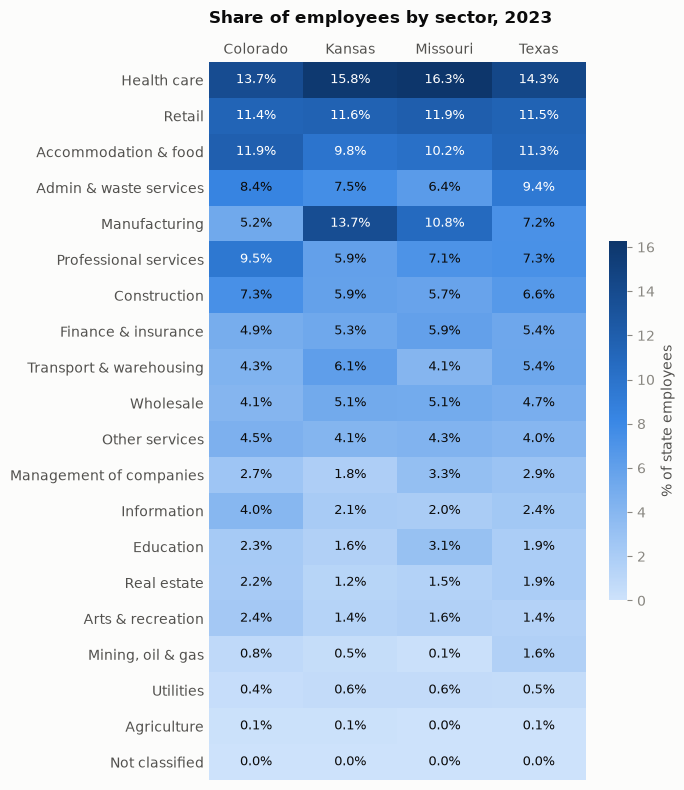

state_name,Colorado,Kansas,Missouri,Texas
sector,,,,
Health care,13.7,15.8,16.3,14.3
Retail,11.4,11.6,11.9,11.5
Accommodation & food,11.9,9.8,10.2,11.3
Admin & waste services,8.4,7.5,6.4,9.4
Manufacturing,5.2,13.7,10.8,7.2
Professional services,9.5,5.9,7.1,7.3
Construction,7.3,5.9,5.7,6.6
Finance & insurance,4.9,5.3,5.9,5.4
Transport & warehousing,4.3,6.1,4.1,5.4


In [3]:
latest = state[state["year"] == 2023]
emp = latest.pivot_table(index="sector", columns="state_name", values="employees")[STATE_ORDER]
share = emp / emp.sum() * 100
share = share.loc[emp.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(share.values, cmap=BLUES, aspect="auto", vmin=0)
ax.set_xticks(range(len(share.columns)), share.columns)
ax.set_yticks(range(len(share.index)), share.index)
ax.tick_params(length=0, colors=INK_2)
ax.xaxis.tick_top()
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.iat[i, j]
        ax.text(j, i, f"{v:.1f}%", ha="center", va="center", fontsize=9,
                color="#ffffff" if v > share.values.max() * 0.55 else INK)
ax.set_title("Share of employees by sector, 2023", loc="left", pad=28)
fig.colorbar(im, ax=ax, shrink=0.5, label="% of state employees").outline.set_visible(False)
plt.tight_layout()
plt.show()

share.round(1)

## Largest sectors by employees, 2023

Top 8 sectors in each state. Axes are not shared: Texas has about 4–10× the employees of the other states.

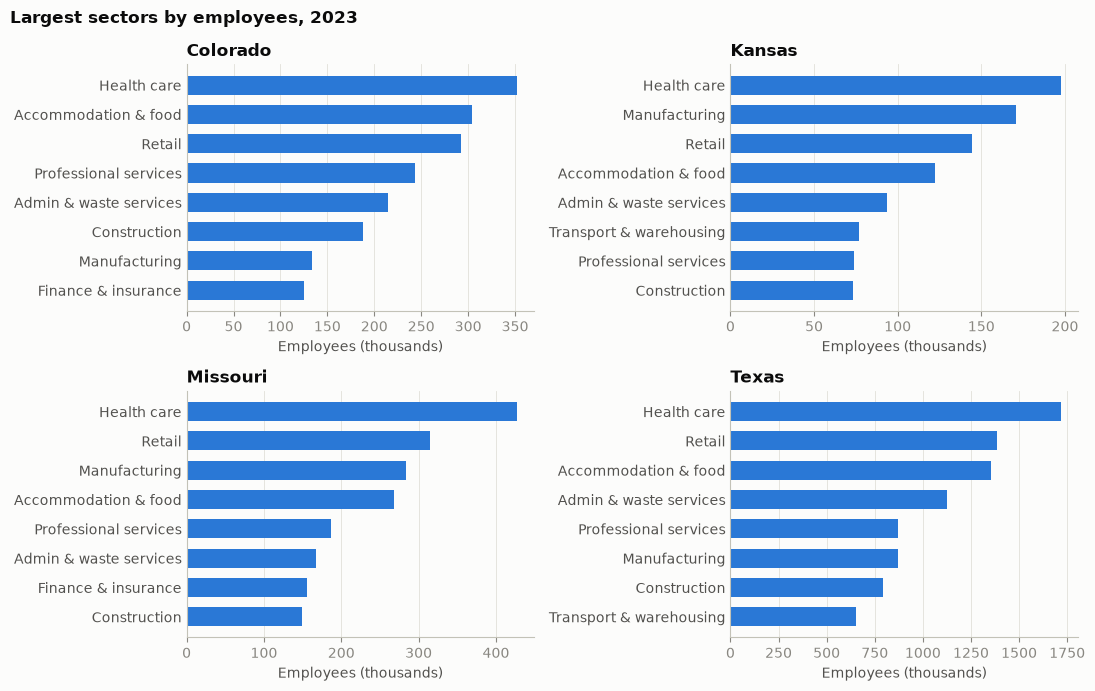

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, name in zip(axes.flat, STATE_ORDER):
    top = latest[latest["state_name"] == name].nlargest(8, "employees").iloc[::-1]
    ax.barh(top["sector"], top["employees"] / 1000, color="#2a78d6", height=0.65)
    ax.set_title(name, loc="left")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0, colors=INK_2)
    ax.set_xlabel("Employees (thousands)")
fig.suptitle("Largest sectors by employees, 2023", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## Year-over-year change, all sectors

Each measure is indexed to 2020 = 100, so states of very different sizes share one axis. Payroll is not adjusted for inflation.

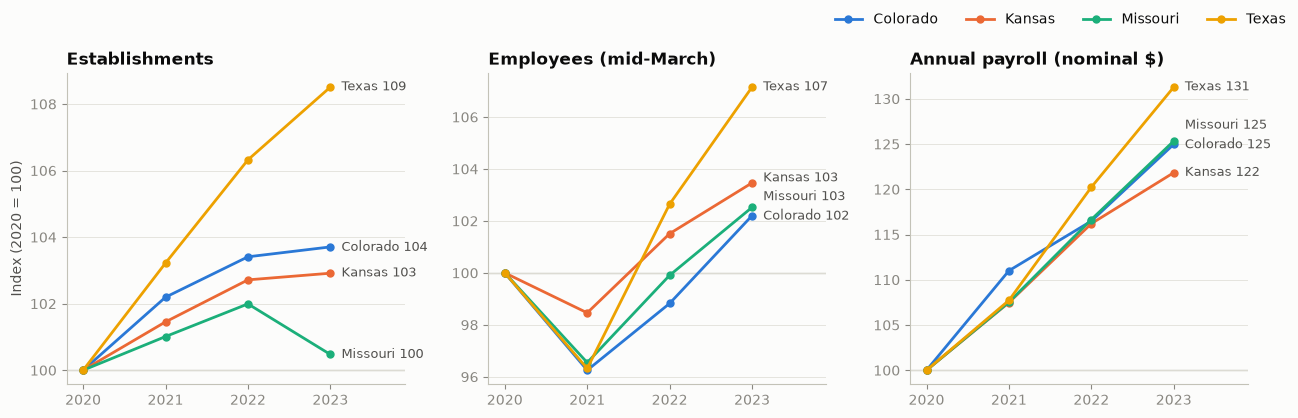

In [5]:
totals = state.groupby(["year", "state_name"])[MEASURES].sum()
index = totals / totals.xs(2020, level="year") * 100
titles = {"establishments": "Establishments", "employees": "Employees (mid-March)",
          "annual_payroll_thousands": "Annual payroll (nominal $)"}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=False)
years = sorted(state["year"].unique())
for ax, measure in zip(axes, MEASURES):
    for name in STATE_ORDER:
        series = index[measure].xs(name, level="state_name")
        ax.plot(series.index, series.values, color=STATE_COLORS[name], marker="o", markersize=5, label=name)
    # Direct labels at the line ends, nudged apart so they don't collide.
    ends = sorted(((index[measure].xs(n, level="state_name").iloc[-1], n) for n in STATE_ORDER))
    span = ax.get_ylim()[1] - ax.get_ylim()[0]
    last_y = -np.inf
    for value, name in ends:
        y = max(value, last_y + span * 0.06)
        ax.annotate(f"{name} {value:.0f}", (years[-1], value), xytext=(8, (y - value) / span * 230),
                    textcoords="offset points", va="center", fontsize=9, color=INK_2)
        last_y = y
    ax.axhline(100, color=AXIS, linewidth=1, zorder=0)
    ax.set_xticks(years)
    ax.set_xlim(years[0] - 0.2, years[-1] + 0.9)
    ax.grid(axis="x", visible=False)
    ax.set_title(titles[measure], loc="left")
axes[0].set_ylabel("Index (2020 = 100)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=4)
plt.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()

In [6]:
# Year-over-year % change by state (table view of the charts above).
yoy = totals.groupby(level="state_name").pct_change().mul(100).round(1).dropna()
yoy.columns = ["establishments %", "employees %", "payroll %"]
yoy.unstack("state_name").swaplevel(axis=1).sort_index(axis=1)[STATE_ORDER]

state_name    Colorado                                 Kansas  \
           employees % establishments % payroll % employees %   
year                                                            
2021              -3.7              2.2      11.0        -1.5   
2022               2.7              1.2       4.9         3.1   
2023               3.4              0.3       7.3         1.9   

state_name                               Missouri                             \
           establishments % payroll % employees % establishments % payroll %   
year                                                                           
2021                    1.5       7.5        -3.5              1.0       7.5   
2022                    1.2       8.1         3.5              1.0       8.5   
2023                    0.2       4.8         2.6             -1.5       7.4   

state_name       Texas                             
           employees % establishments % payroll %  
year                                               
2021              -3.7              3.2       7.7  
2022               6.6              3.0      11.6  
2023               4.4              2.1       9.2

## Which sectors grew? Employees, 2020 → 2023

Blue = growth, red = decline, gray = little change. Colors are capped at ±30% so extreme small sectors don't wash out the rest; the cell labels show the exact value.

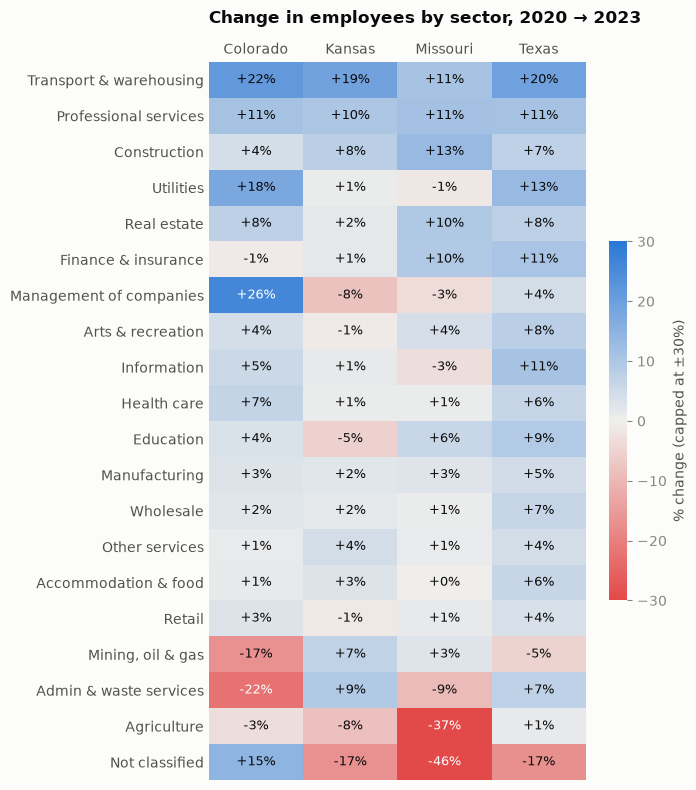

state_name,Colorado,Kansas,Missouri,Texas
sector,,,,
Transport & warehousing,21.5,19.0,11.0,19.6
Professional services,11.1,10.2,11.3,11.2
Construction,4.2,8.0,13.1,7.4
Utilities,17.9,0.9,-1.4,13.3
Real estate,7.6,1.8,9.8,7.5
Finance & insurance,-0.8,1.5,9.6,10.6
Management of companies,25.8,-8.2,-3.3,4.2
Arts & recreation,4.2,-0.8,3.9,8.2
Information,5.4,1.4,-2.9,11.0


In [7]:
emp_by = state.pivot_table(index=["sector", "year"], columns="state_name", values="employees")[STATE_ORDER]
change = (emp_by.xs(2023, level="year") / emp_by.xs(2020, level="year") - 1) * 100
change = change.loc[change.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(change.values, cmap=RED_GRAY_BLUE, vmin=-30, vmax=30, aspect="auto")
ax.set_xticks(range(len(change.columns)), change.columns)
ax.set_yticks(range(len(change.index)), change.index)
ax.tick_params(length=0, colors=INK_2)
ax.xaxis.tick_top()
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(change.shape[0]):
    for j in range(change.shape[1]):
        v = change.iat[i, j]
        ax.text(j, i, f"{v:+.0f}%", ha="center", va="center", fontsize=9,
                color="#ffffff" if abs(v) > 22 else INK)
ax.set_title("Change in employees by sector, 2020 → 2023", loc="left", pad=28)
fig.colorbar(im, ax=ax, shrink=0.5, label="% change (capped at ±30%)").outline.set_visible(False)
plt.tight_layout()
plt.show()

change.round(1)

## One state, sector by sector

Change `STATE` to look at another state. Shows employees each year and the year-over-year % change.

In [8]:
STATE = "Kansas"

one = state[state["state_name"] == STATE].pivot_table(index="sector", columns="year", values="employees")
one = one.sort_values(2023, ascending=False)
pct = one.pct_change(axis=1).mul(100).round(1).drop(columns=2020)
pct.columns = [f"{y} YoY %" for y in pct.columns]
one.join(pct)

,2020,2021,2022,2023,2021 YoY %,2022 YoY %,2023 YoY %
sector,,,,,,,
Health care,195983.0,191385.0,192702.0,197779.0,-2.3,0.7,2.6
Manufacturing,166901.0,161437.0,167278.0,170492.0,-3.3,3.6,1.9
Retail,146028.0,143852.0,144030.0,144418.0,-1.5,0.1,0.3
Accommodation & food,118605.0,110604.0,117287.0,122184.0,-6.7,6.0,4.2
Admin & waste services,85529.0,92953.0,97256.0,93621.0,8.7,4.6,-3.7
Transport & warehousing,64377.0,64704.0,69878.0,76636.0,0.5,8.0,9.7
Professional services,67042.0,69169.0,72590.0,73893.0,3.2,4.9,1.8
Construction,67995.0,69246.0,70546.0,73436.0,1.8,1.9,4.1
Finance & insurance,65011.0,67424.0,66881.0,65980.0,3.7,-0.8,-1.3


## County view

Counties with at least 100 establishments in 2020, ranked by establishment growth to 2023. County totals here are sums of sector rows, which run slightly below official county totals because CBP withholds some small cells.

In [9]:
by_county = county.groupby(["county_fips", "county_name", "year"])[MEASURES].sum().unstack("year")
est = by_county["establishments"]
growth = pd.DataFrame({
    "establishments 2020": est[2020],
    "establishments 2023": est[2023],
    "change %": (est[2023] / est[2020] - 1) * 100,
    "employees 2023": by_county["employees"][2023],
}).dropna()  # drops counties missing 2020 or 2023
growth = growth.astype({"establishments 2020": int, "establishments 2023": int, "employees 2023": int})
growth = growth[growth["establishments 2020"] >= 100]

print("Fastest-growing counties by establishments")
display(growth.nlargest(15, "change %").round(1))
print("Largest counties by employees, 2023")
display(growth.nlargest(10, "employees 2023").round(1))

Fastest-growing counties by establishments


,,establishments 2020,establishments 2023,change %,employees 2023
county_fips,county_name,,,,
48473,"Waller County, Texas",859,1081,25.8,18058
48407,"San Jacinto County, Texas",203,253,24.6,1417
48209,"Hays County, Texas",4807,5891,22.6,76995
48053,"Burnet County, Texas",1319,1598,21.2,15324
48491,"Williamson County, Texas",12467,15041,20.6,203878
48157,"Fort Bend County, Texas",15378,18519,20.4,222203
48377,"Presidio County, Texas",118,142,20.3,943
48121,"Denton County, Texas",16716,20025,19.8,280349
48091,"Comal County, Texas",4137,4951,19.7,65657


Largest counties by employees, 2023


,,establishments 2020,establishments 2023,change %,employees 2023
county_fips,county_name,,,,
48201,"Harris County, Texas",105710,111215,5.2,2182164
48113,"Dallas County, Texas",68180,71182,4.4,1648702
48439,"Tarrant County, Texas",44319,47656,7.5,882289
48029,"Bexar County, Texas",37198,39726,6.8,821509
48453,"Travis County, Texas",38547,42837,11.1,736608
29189,"St. Louis County, Missouri",30897,29717,-3.8,629036
48085,"Collin County, Texas",26472,31012,17.2,528596
08031,"Denver County, Colorado",26817,27422,2.3,489563
29095,"Jackson County, Missouri",18084,18212,0.7,360017


In [10]:
# How much of each state's activity the county rows capture (withheld cells make it < 100%).
county_sum = county.groupby(["year", "state_name"])[MEASURES].sum()
(county_sum / totals * 100).round(1).xs(2023, level="year")

,establishments,employees,annual_payroll_thousands
state_name,,,
Colorado,99.3,95.9,95.2
Kansas,98.3,95.2,95.4
Missouri,99.1,96.5,95.4
Texas,99.6,94.9,94.3
